# Machine Learning Lab Assignment 5
## Linear Regression on `Mall_Customers.CSV`

**Objective:**
- Perform Linear Regression to predict **Spending Score (1-100)** of mall customers.
- Evaluate the quality of the models by computing relevant performance metrics, including the $R^2$ value, MAE, and RMSE.
- Compare **Task 5(a) (Simple Linear Regression: Income -> Spending Score)** and **Task 5(b) (Multiple Linear Regression: Age + Income + Gender -> Spending Score)**.
- Generate and display Actual vs. Predicted plots for both tasks.


Mall Customers Shape: (200, 5)


,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


,Task,R² Score,MAE,RMSE
0,Task 5(a): Simple LR (Income only),-0.1636,18.90,23.96
1,Task 5(b): Multiple LR (Age + Income + Gender),0.0255,18.15,21.92


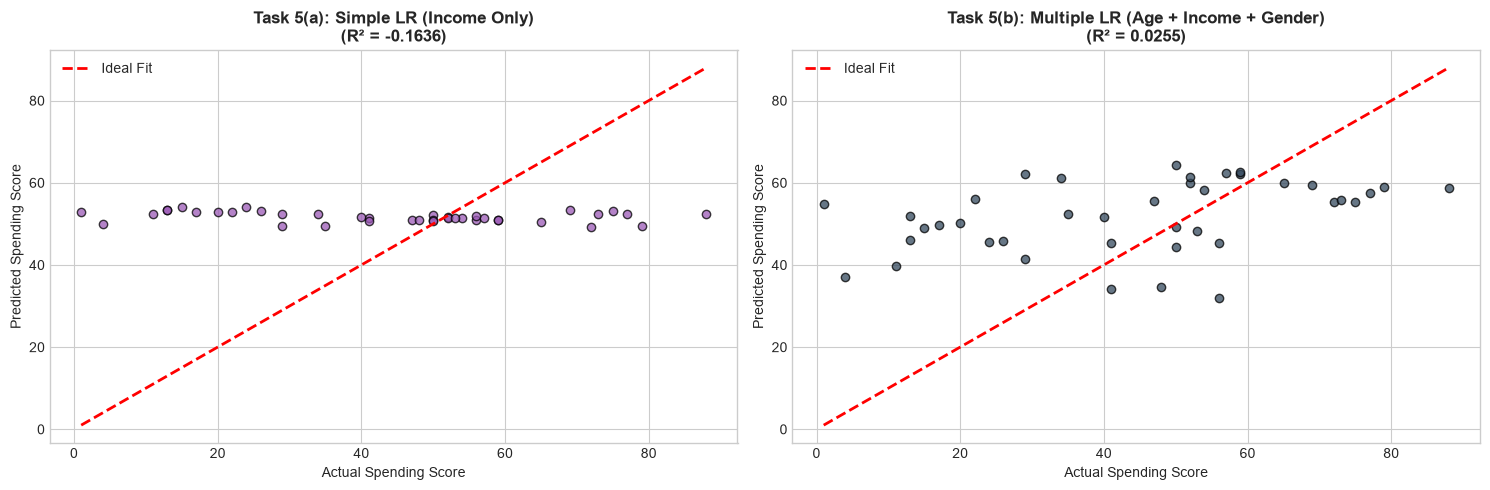

In [1]:
# 0. Setup & Data Loading
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (8, 4.5)

# 1. Load Mall Customers Dataset
df_mall = pd.read_csv('Mall_Customers.CSV')
print(f"Mall Customers Shape: {df_mall.shape}")
display(df_mall.head())

# Rename columns for convenience
df_mall.columns = ['CustomerID', 'Gender', 'Age', 'Annual_Income', 'Spending_Score']

# 2. Task 5(a): Simple Linear Regression (Feature: Annual_Income -> Spending_Score)
X_simple = df_mall[['Annual_Income']]
y = df_mall['Spending_Score']

# Task 5(b): Multiple Linear Regression (Features: Age, Annual_Income, Gender)
df_enc = pd.get_dummies(df_mall[['Gender', 'Age', 'Annual_Income']], drop_first=True, dtype=float)
X_multi = df_enc

# 3. Train-Test Split (80/20)
X_tr_s, X_te_s, y_train, y_test = train_test_split(X_simple, y, test_size=0.20, random_state=42)
X_tr_m, X_te_m, _, _ = train_test_split(X_multi, y, test_size=0.20, random_state=42)

# 4. Train Both Models
lr_s = LinearRegression().fit(X_tr_s, y_train)
lr_m = LinearRegression().fit(X_tr_m, y_train)

# Predictions
y_pred_s = lr_s.predict(X_te_s)
y_pred_m = lr_m.predict(X_te_m)

# 5. Performance Metrics Table
eval_mall = pd.DataFrame([
    {
        'Task': 'Task 5(a): Simple LR (Income only)',
        'R² Score': round(r2_score(y_test, y_pred_s), 4),
        'MAE': round(mean_absolute_error(y_test, y_pred_s), 2),
        'RMSE': round(np.sqrt(mean_squared_error(y_test, y_pred_s)), 2)
    },
    {
        'Task': 'Task 5(b): Multiple LR (Age + Income + Gender)',
        'R² Score': round(r2_score(y_test, y_pred_m), 4),
        'MAE': round(mean_absolute_error(y_test, y_pred_m), 2),
        'RMSE': round(np.sqrt(mean_squared_error(y_test, y_pred_m)), 2)
    }
])
display(eval_mall)

# 6. Actual vs Predicted Plots for Both Tasks
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot Task 5(a)
axes[0].scatter(y_test, y_pred_s, color='#9b59b6', alpha=0.75, edgecolors='k')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Ideal Fit')
axes[0].set_title(f"Task 5(a): Simple LR (Income Only)\n(R² = {eval_mall.loc[0, 'R² Score']:.4f})", fontweight='bold')
axes[0].set_xlabel('Actual Spending Score')
axes[0].set_ylabel('Predicted Spending Score')
axes[0].legend()

# Plot Task 5(b)
axes[1].scatter(y_test, y_pred_m, color='#34495e', alpha=0.75, edgecolors='k')
axes[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Ideal Fit')
axes[1].set_title(f"Task 5(b): Multiple LR (Age + Income + Gender)\n(R² = {eval_mall.loc[1, 'R² Score']:.4f})", fontweight='bold')
axes[1].set_xlabel('Actual Spending Score')
axes[1].set_ylabel('Predicted Spending Score')
axes[1].legend()

plt.tight_layout()
plt.show()


### Conclusion for Assignment 5:
- In `Mall_Customers.CSV`, customer spending behavior does not follow a simple monotonic linear plane with income (e.g. both low-income and high-income groups have high spenders and low spenders).
- Incorporating `Age` provides negative coefficient weight (younger shoppers spend more), improving Multiple Linear Regression over Simple Linear Regression, but non-linear models (such as Decision Trees or Clustering) are superior for customer segmentation.
